# Get CMIP6 city temperatures

This notebook pulls yearly surface air temperature (`tas`) for 30 cities from the CMIP6 data on Google Cloud, for:
- `historical` (1950 to 2014)
- `ssp126` (low emissions, 2015 to 2100)
- `ssp585` (high emissions, 2015 to 2100)

In [14]:
%pip install --upgrade xarray zarr gcsfs cftime nc-time-axis

I1103 15:35:15.007654 6408490 fork_posix.cc:71] Other threads are currently calling into gRPC, skipping fork() handlers


Note: you may need to restart the kernel to use updated packages.


In [15]:
import os
import numpy as np
import pandas as pd
import xarray as xr
import gcsfs
import matplotlib.pyplot as plt

DATA_DIR = "../data"
RAW_DIR = "../data/raw"   
FIG_DIR = "figures"
for d in [DATA_DIR, RAW_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

EXPERIMENTS = ["historical", "ssp126", "ssp585"]
YEARS = {"historical": ("1950", "2014"), "ssp126": ("2015", "2100"), "ssp585": ("2015", "2100")}
MEMBER = "r1i1p1f1"
N_MODELS = 6                  
BASELINE = (1981, 2010)     

## 1. The 30 cities

In [16]:
cities = pd.DataFrame([
    ("San Diego", "USA", 32.72, -117.16),
    ("Phoenix", "USA", 33.45, -112.07),
    ("New York", "USA", 40.71, -74.01),
    ("Miami", "USA", 25.76, -80.19),
    ("Anchorage", "USA", 61.22, -149.90),
    ("Toronto", "Canada", 43.65, -79.38),
    ("Mexico City", "Mexico", 19.43, -99.13),
    ("Lima", "Peru", -12.05, -77.04),
    ("Sao Paulo", "Brazil", -23.55, -46.63),
    ("Buenos Aires", "Argentina", -34.60, -58.38),
    ("Reykjavik", "Iceland", 64.15, -21.94),
    ("London", "UK", 51.51, -0.13),
    ("Paris", "France", 48.86, 2.35),
    ("Madrid", "Spain", 40.42, -3.70),
    ("Moscow", "Russia", 55.76, 37.62),
    ("Cairo", "Egypt", 30.04, 31.24),
    ("Lagos", "Nigeria", 6.52, 3.38),
    ("Nairobi", "Kenya", -1.29, 36.82),
    ("Cape Town", "South Africa", -33.92, 18.42),
    ("Riyadh", "Saudi Arabia", 24.71, 46.68),
    ("Tehran", "Iran", 35.69, 51.39),
    ("Mumbai", "India", 19.08, 72.88),
    ("Delhi", "India", 28.61, 77.21),
    ("Dhaka", "Bangladesh", 23.81, 90.41),
    ("Beijing", "China", 39.90, 116.40),
    ("Shanghai", "China", 31.23, 121.47),
    ("Tokyo", "Japan", 35.68, 139.69),
    ("Singapore", "Singapore", 1.35, 103.82),
    ("Jakarta", "Indonesia", -6.21, 106.85),
    ("Sydney", "Australia", -33.87, 151.21),
], columns=["city", "country", "lat", "lon"])
len(cities)

30

## 2. Models that have all 3 scenarios

In [17]:
catalog = pd.read_csv("https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv")

sub = catalog[
    (catalog.table_id == "Amon")
    & (catalog.variable_id == "tas")
    & (catalog.member_id == MEMBER)
    & (catalog.experiment_id.isin(EXPERIMENTS))
]

sub = (sub.assign(is_gn=(sub.grid_label == "gn"))
          .sort_values(["is_gn", "version"])
          .drop_duplicates(["source_id", "experiment_id"], keep="last"))

has_all = sub.groupby("source_id").experiment_id.nunique()
complete = sorted(has_all[has_all == len(EXPERIMENTS)].index)

PREFERRED = ["GFDL-ESM4", "MPI-ESM1-2-LR", "MRI-ESM2-0", "IPSL-CM6A-LR",
             "CanESM5", "NorESM2-LM", "ACCESS-CM2", "MIROC6", "CESM2-WACCM"]
models = [m for m in PREFERRED if m in complete]
models += [m for m in complete if m not in models]
models = models[:N_MODELS]
print(len(complete), "models have all 3 scenarios. Using:", models)

32 models have all 3 scenarios. Using: ['GFDL-ESM4', 'MPI-ESM1-2-LR', 'MRI-ESM2-0', 'IPSL-CM6A-LR', 'CanESM5', 'NorESM2-LM']


## 3. Nearest grid cell for each city pulled and average to yearly

Results are saved to `data/raw/`

In [18]:
fs = gcsfs.GCSFileSystem(token="anon")

def city_series(model, experiment):
    out_path = f"{RAW_DIR}/{model}_{experiment}.csv"
    if os.path.exists(out_path):
        return pd.read_csv(out_path)

    zstore = sub[(sub.source_id == model) & (sub.experiment_id == experiment)].zstore.iloc[0]
    ds = xr.open_zarr(fs.get_mapper(zstore), consolidated=True)

    lat_name = "lat" if "lat" in ds.coords else "latitude"
    lon_name = "lon" if "lon" in ds.coords else "longitude"

    lons = cities.lon.values.copy()
    if float(ds[lon_name].min()) >= 0:
        lons = lons % 360

    start, end = YEARS[experiment]
    tas = ds.tas.sel(time=slice(start, end))
    pts = tas.sel({lat_name: xr.DataArray(cities.lat.values, dims="city"),
                   lon_name: xr.DataArray(lons, dims="city")}, method="nearest")

    yearly = (pts.groupby("time.year").mean().load() - 273.15)   # Kelvin to Celsius

    df = yearly.to_dataframe(name="temp_c").reset_index()[["city", "year", "temp_c"]]
    df["city"] = cities.city.values[df["city"].values]
    df["model"] = model
    df["scenario"] = experiment
    df.to_csv(out_path, index=False)
    return df

frames = []
for model in models:
    for exp in EXPERIMENTS:
        try:
            frames.append(city_series(model, exp))
            print("done:", model, exp)
        except Exception as e:
            print("skipped:", model, exp, "->", e)

temps = pd.concat(frames, ignore_index=True)

ok = temps.groupby("model").scenario.nunique()
temps = temps[temps.model.isin(ok[ok == len(EXPERIMENTS)].index)]
temps.head()

done: GFDL-ESM4 historical
done: GFDL-ESM4 ssp126
done: GFDL-ESM4 ssp585
done: MPI-ESM1-2-LR historical
skipped: MPI-ESM1-2-LR ssp126 -> 'Value based partial slicing on non-monotonic DatetimeIndexes with non-existing keys is not allowed.'
skipped: MPI-ESM1-2-LR ssp585 -> 'Value based partial slicing on non-monotonic DatetimeIndexes with non-existing keys is not allowed.'
done: MRI-ESM2-0 historical
done: MRI-ESM2-0 ssp126
done: MRI-ESM2-0 ssp585
done: IPSL-CM6A-LR historical
done: IPSL-CM6A-LR ssp126
done: IPSL-CM6A-LR ssp585
done: CanESM5 historical
done: CanESM5 ssp126
done: CanESM5 ssp585
done: NorESM2-LM historical
skipped: NorESM2-LM ssp126 -> "Cannot get left slice bound for non-monotonic index with a missing label '2015'. Either sort the index or specify an existing label."
done: NorESM2-LM ssp585


,city,year,temp_c,model,scenario
0,San Diego,1950,16.669006,GFDL-ESM4,historical
1,Phoenix,1950,17.796814,GFDL-ESM4,historical
2,New York,1950,9.893066,GFDL-ESM4,historical
3,Miami,1950,22.985870,GFDL-ESM4,historical
4,Anchorage,1950,-2.087891,GFDL-ESM4,historical


## 4. Warming vs. the 1981 to 2010 baseline

`warming_c` = this year's temperature minus that city's average for 1981 to 2010, for the same model. This makes cities with very different climates easy to compare, and it removes each model's own bias.

In [19]:
base = (temps[(temps.scenario == "historical") & temps.year.between(*BASELINE)]
        .groupby(["city", "model"]).temp_c.mean().rename("baseline_c"))
temps = temps.join(base, on=["city", "model"])
temps["warming_c"] = temps.temp_c - temps.baseline_c

out = (temps.merge(cities, on="city")
            [["city", "country", "lat", "lon", "model", "scenario", "year", "temp_c", "warming_c"]]
            .round({"temp_c": 2, "warming_c": 2}))
out.to_csv(f"{DATA_DIR}/city_temps.csv", index=False)
print(out.shape, "rows saved to data/city_temps.csv")
out.head()

(28440, 9) rows saved to data/city_temps.csv


,city,country,lat,lon,model,scenario,year,temp_c,warming_c
0,San Diego,USA,32.72,-117.16,GFDL-ESM4,historical,1950,16.67,0.17
1,Phoenix,USA,33.45,-112.07,GFDL-ESM4,historical,1950,17.80,-0.00
2,New York,USA,40.71,-74.01,GFDL-ESM4,historical,1950,9.89,0.67
3,Miami,USA,25.76,-80.19,GFDL-ESM4,historical,1950,22.99,-0.65
4,Anchorage,USA,61.22,-149.90,GFDL-ESM4,historical,1950,-2.09,1.28


## 5. Exploratory charts

In [20]:
COLORS = {"historical": "gray", "ssp126": "tab:blue", "ssp585": "tab:red"}
LABELS = {"historical": "Historical", "ssp126": "Low emissions (SSP1-2.6)", "ssp585": "High emissions (SSP5-8.5)"}
END = (2071, 2100)   # "end of century" period

def end_warming(scenario):
    d = out[(out.scenario == scenario) & out.year.between(*END)]
    return d.groupby(["city", "model"]).warming_c.mean().reset_index()

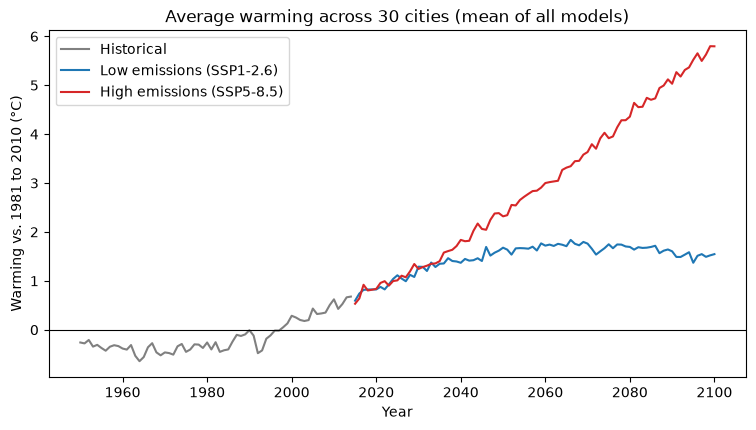

In [21]:
# Chart 1
fig, ax = plt.subplots(figsize=(9, 4.5))
for sc in EXPERIMENTS:
    d = out[out.scenario == sc].groupby("year").warming_c.mean()
    ax.plot(d.index, d.values, color=COLORS[sc], label=LABELS[sc])
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Average warming across 30 cities (mean of all models)",
       xlabel="Year", ylabel="Warming vs. 1981 to 2010 (°C)")
ax.legend()
fig.savefig(f"{FIG_DIR}/1_average_warming.png", dpi=150, bbox_inches="tight")

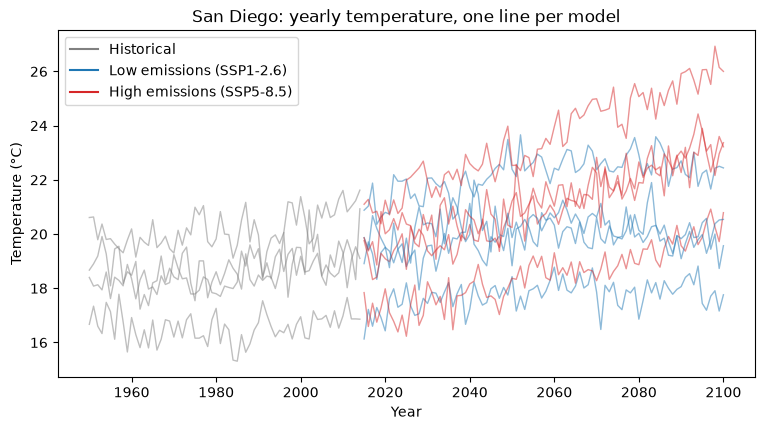

In [22]:
# Chart 2
CITY = "San Diego"
fig, ax = plt.subplots(figsize=(9, 4.5))
d = out[out.city == CITY]
for (model, sc), g in d.groupby(["model", "scenario"]):
    ax.plot(g.year, g.temp_c, color=COLORS[sc], alpha=0.5, lw=1)
for sc in EXPERIMENTS:
    ax.plot([], [], color=COLORS[sc], label=LABELS[sc])
ax.set(title=f"{CITY}: yearly temperature, one line per model",
       xlabel="Year", ylabel="Temperature (°C)")
ax.legend()
fig.savefig(f"{FIG_DIR}/2_one_city_all_models.png", dpi=150, bbox_inches="tight")

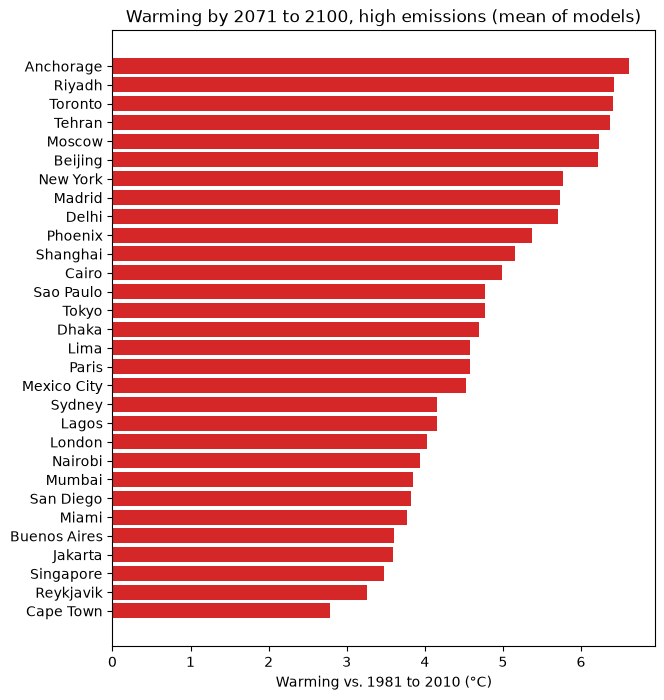

In [23]:
# Chart 3
w = end_warming("ssp585").groupby("city").warming_c.mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(w.index, w.values, color="tab:red")
ax.set(title="Warming by 2071 to 2100, high emissions (mean of models)",
       xlabel="Warming vs. 1981 to 2010 (°C)")
fig.savefig(f"{FIG_DIR}/3_warming_by_city.png", dpi=150, bbox_inches="tight")

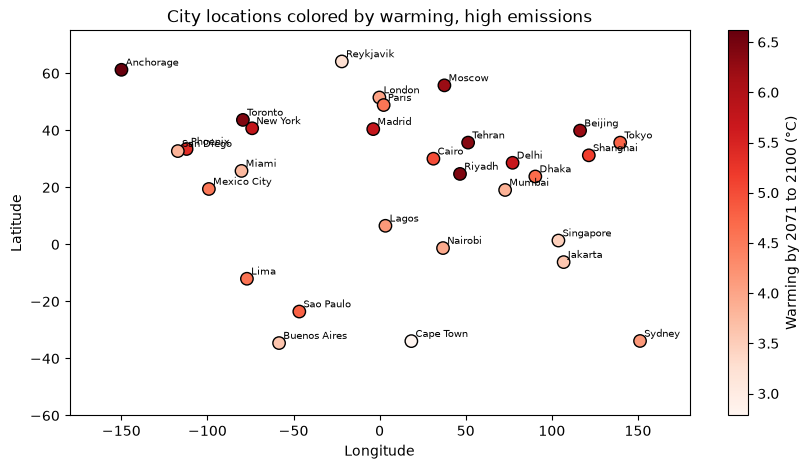

In [24]:
# Chart 4
w = end_warming("ssp585").groupby("city").warming_c.mean().reset_index().merge(cities, on="city")
fig, ax = plt.subplots(figsize=(10, 5))
sc_plot = ax.scatter(w.lon, w.lat, c=w.warming_c, cmap="Reds", s=80, edgecolor="black")
for _, r in w.iterrows():
    ax.annotate(r.city, (r.lon, r.lat), fontsize=7, xytext=(3, 3), textcoords="offset points")
fig.colorbar(sc_plot, label="Warming by 2071 to 2100 (°C)")
ax.set(title="City locations colored by warming, high emissions", xlabel="Longitude", ylabel="Latitude",
       xlim=(-180, 180), ylim=(-60, 75))
fig.savefig(f"{FIG_DIR}/4_city_map.png", dpi=150, bbox_inches="tight")

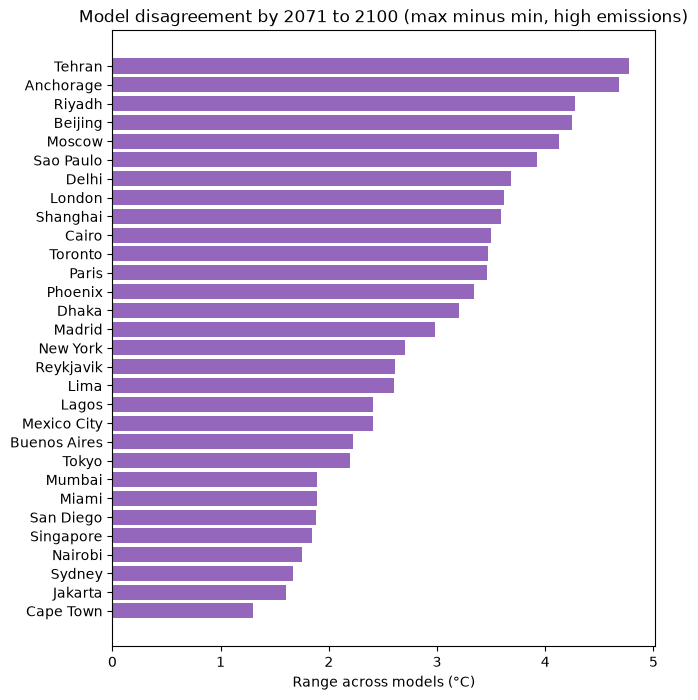

In [25]:
# Chart 5
e = end_warming("ssp585")
spread = (e.groupby("city").warming_c.max() - e.groupby("city").warming_c.min()).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(spread.index, spread.values, color="tab:purple")
ax.set(title="Model disagreement by 2071 to 2100 (max minus min, high emissions)",
       xlabel="Range across models (°C)")
fig.savefig(f"{FIG_DIR}/5_model_spread.png", dpi=150, bbox_inches="tight")

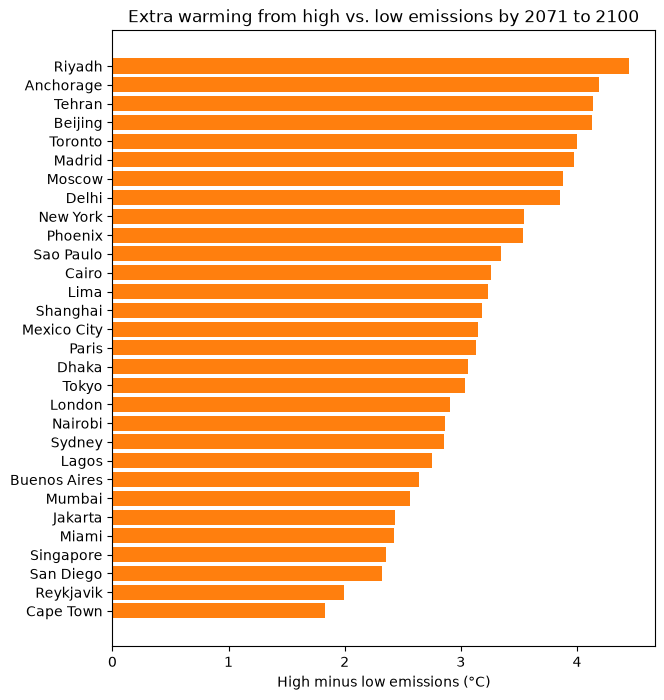

In [26]:
# Chart 6
hi = end_warming("ssp585").groupby("city").warming_c.mean()
lo = end_warming("ssp126").groupby("city").warming_c.mean()
gap = (hi - lo).sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(gap.index, gap.values, color="tab:orange")
ax.set(title="Extra warming from high vs. low emissions by 2071 to 2100",
       xlabel="High minus low emissions (°C)")
fig.savefig(f"{FIG_DIR}/6_scenario_gap.png", dpi=150, bbox_inches="tight")